In [3]:
# CÂU 1)
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import urllib.request
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Tự động tải file Mall_Customers.csv nếu chưa có trong thư mục
url = "https://raw.githubusercontent.com/vjchoudhary7/Customer-Segmentation-Tutorial-in-Python/master/Mall_Customers.csv"
if not os.path.exists("Mall_Customers.csv"):
    urllib.request.urlretrieve(url, "Mall_Customers.csv")

# 1. Đọc dữ liệu
df = pd.read_csv("Mall_Customers.csv")

# 2. Thống kê thông tin cơ bản
print("--- THÔNG TIN CƠ BẢN CỦA DỮ LIỆU ---")
print(df.info())
print("\n5 dòng đầu tiên của dữ liệu:")
print(df.head())

print("\nThống kê mô tả (describe):")
print(df.describe())

# 3. Kiểm tra và xử lý dữ liệu bị thiếu (missing values)
print("\nSố lượng giá trị bị thiếu trong từng cột:")
print(df.isnull().sum())

Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64
--- THÔNG TIN CƠ BẢN CỦA DỮ LIỆU ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None

5 dòng đầu tiên của dữ liệu:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                  

Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64


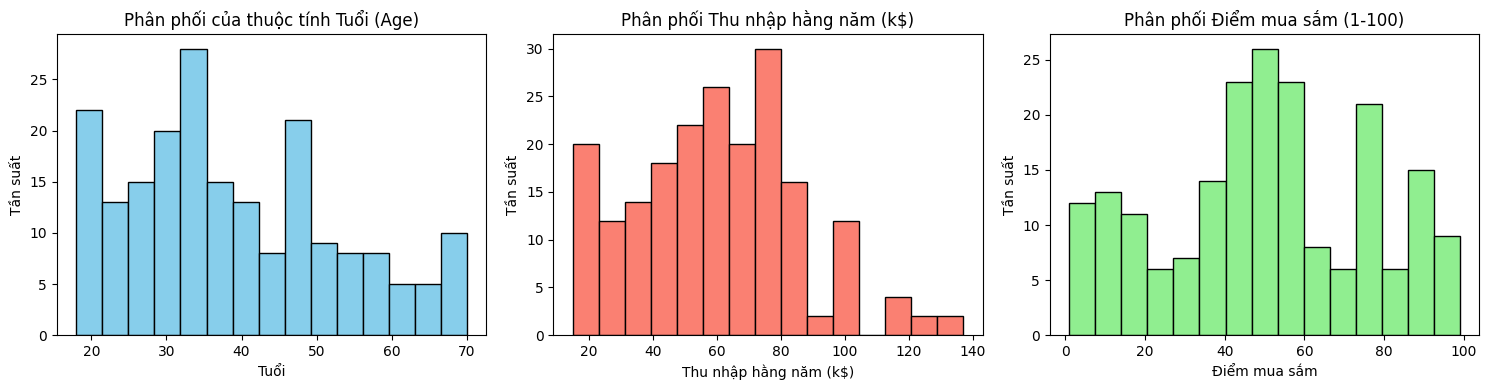

In [4]:
# CÂU 2)
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

plt.figure(figsize=(15, 4))

# Phân phối Tuổi
plt.subplot(1, 3, 1)
plt.hist(df['Age'], bins=15, color='skyblue', edgecolor='black')
plt.title('Phân phối của thuộc tính Tuổi (Age)')
plt.xlabel('Tuổi')
plt.ylabel('Tần suất')

# Phân phối Thu nhập hằng năm
plt.subplot(1, 3, 2)
plt.hist(df['Annual Income (k$)'], bins=15, color='salmon', edgecolor='black')
plt.title('Phân phối Thu nhập hằng năm (k$)')
plt.xlabel('Thu nhập hằng năm (k$)')
plt.ylabel('Tần suất')

# Phân phối Điểm mua sắm
plt.subplot(1, 3, 3)
plt.hist(df['Spending Score (1-100)'], bins=15, color='lightgreen', edgecolor='black')
plt.title('Phân phối Điểm mua sắm (1-100)')
plt.xlabel('Điểm mua sắm')
plt.ylabel('Tần suất')

plt.tight_layout()
plt.show()

Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64
Số mẫu dữ liệu theo từng giới tính:
Gender
Female    112
Male       88
Name: count, dtype: int64


/tmp/ipykernel_1052/2759428503.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Gender', palette=['#3498db', '#e74c3c'])


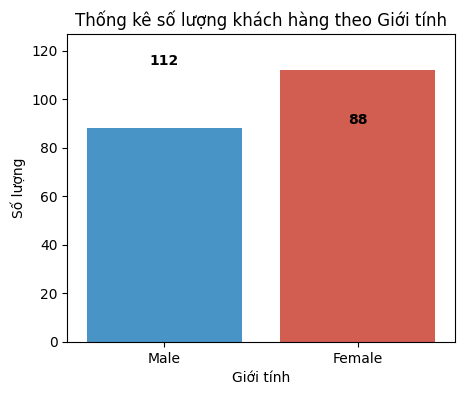

In [5]:
# CÂU 3)
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

# Thống kê số lượng theo giới tính
gender_counts = df['Gender'].value_counts()
print("Số mẫu dữ liệu theo từng giới tính:")
print(gender_counts)

# Vẽ biểu đồ cột
plt.figure(figsize=(5, 4))
sns.countplot(data=df, x='Gender', palette=['#3498db', '#e74c3c'])
plt.title("Thống kê số lượng khách hàng theo Giới tính")
plt.xlabel("Giới tính")
plt.ylabel("Số lượng")

# Hiển thị số lượng cụ thể trên đầu cột
for i, count in enumerate(gender_counts):
    plt.text(i, count + 2, str(count), ha='center', fontweight='bold')

plt.ylim(0, max(gender_counts) + 15)
plt.show()

Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64


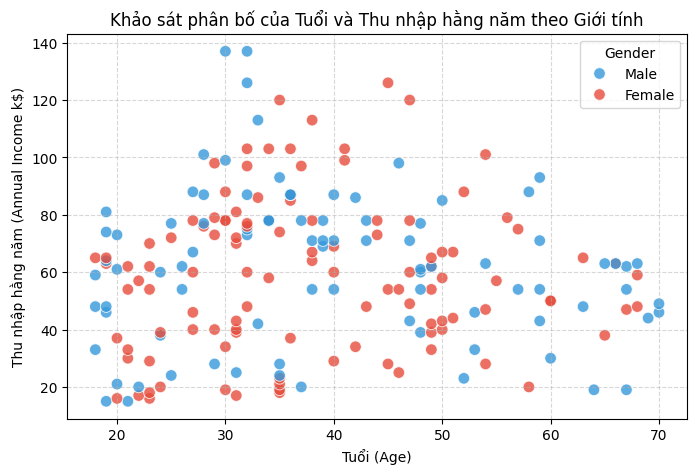

In [6]:
# CÂU 4)
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x='Age',
    y='Annual Income (k$)',
    hue='Gender',
    palette=['#3498db', '#e74c3c'],
    s=70,
    alpha=0.8
)
plt.title("Khảo sát phân bố của Tuổi và Thu nhập hằng năm theo Giới tính")
plt.xlabel("Tuổi (Age)")
plt.ylabel("Thu nhập hằng năm (Annual Income k$)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64


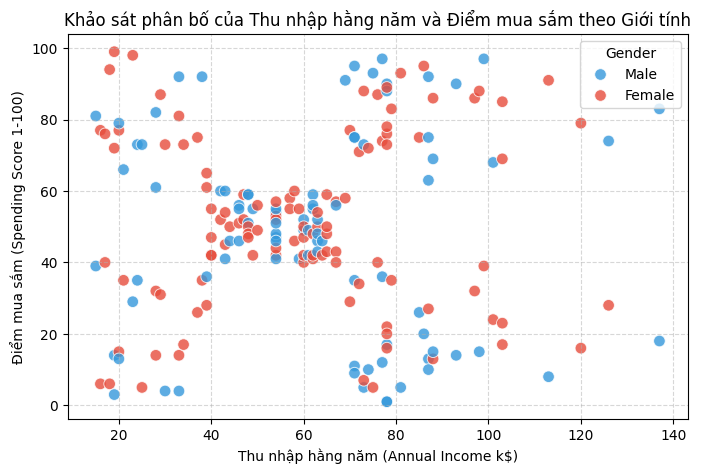

In [7]:
# CÂU 5)
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Gender',
    palette=['#3498db', '#e74c3c'],
    s=70,
    alpha=0.8
)
plt.title("Khảo sát phân bố của Thu nhập hằng năm và Điểm mua sắm theo Giới tính")
plt.xlabel("Thu nhập hằng năm (Annual Income k$)")
plt.ylabel("Điểm mua sắm (Spending Score 1-100)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64


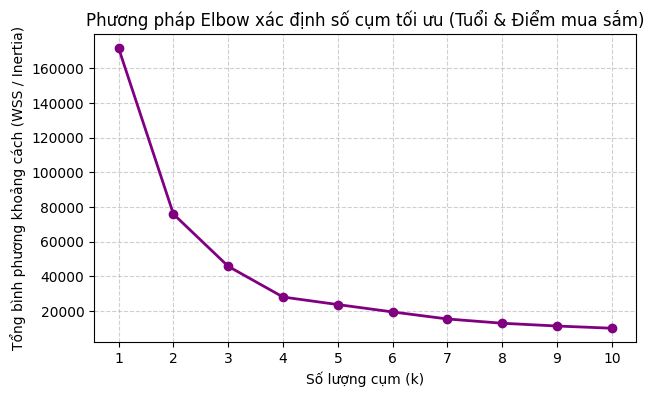

=> Vị trí khuỷu tay cho thấy số cụm tối ưu là k = 4.
Đã hoàn thành gom cụm bằng thuật toán K-Means với k = 4.


In [8]:
# CÂU 6)
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

# Lấy 2 thuộc tính Tuổi và Điểm mua sắm
X_age_spending = df[['Age', 'Spending Score (1-100)']].values

# Tính tổng bình phương khoảng cách (Inertia/WSS) cho k từ 1 đến 10
inertia_list = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    km.fit(X_age_spending)
    inertia_list.append(km.inertia_)

# Vẽ biểu đồ Elbow
plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), inertia_list, marker='o', color='purple', linewidth=2)
plt.title("Phương pháp Elbow xác định số cụm tối ưu (Tuổi & Điểm mua sắm)")
plt.xlabel("Số lượng cụm (k)")
plt.ylabel("Tổng bình phương khoảng cách (WSS / Inertia)")
plt.xticks(range(1, 11))
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Điểm gập khuỷu tay xác định số cụm tối ưu k = 4 (theo hướng dẫn trang 22)
print("=> Vị trí khuỷu tay cho thấy số cụm tối ưu là k = 4.")
kmeans_age_spending = KMeans(n_clusters=4, init='k-means++', random_state=42, n_init=10)
clusters_age_spending = kmeans_age_spending.fit_predict(X_age_spending)
print("Đã hoàn thành gom cụm bằng thuật toán K-Means với k = 4.")

Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64


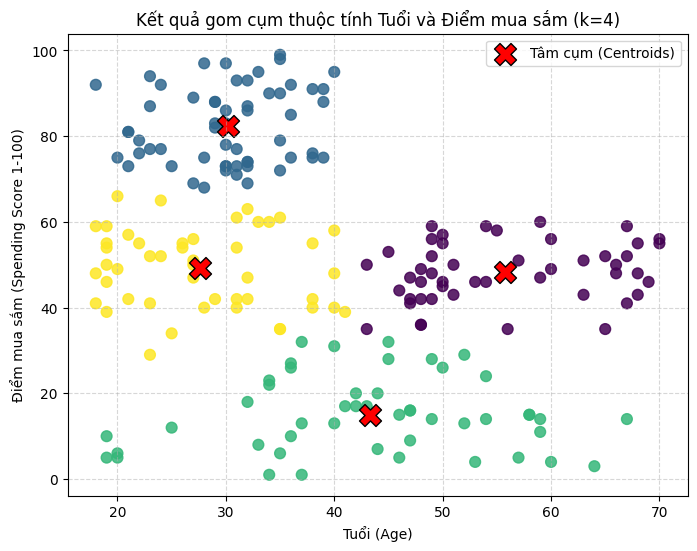

In [9]:
# CÂU 7)
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

plt.figure(figsize=(8, 6))
plt.scatter(X_age_spending[:, 0], X_age_spending[:, 1], c=clusters_age_spending, cmap='viridis', s=60, alpha=0.85)

# Vẽ tâm các cụm
centers = kmeans_age_spending.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=250, marker='X', label='Tâm cụm (Centroids)', edgecolor='black')

plt.title("Kết quả gom cụm thuộc tính Tuổi và Điểm mua sắm (k=4)")
plt.xlabel("Tuổi (Age)")
plt.ylabel("Điểm mua sắm (Spending Score 1-100)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [10]:
# CÂU 8)
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

sil_score = silhouette_score(X_age_spending, clusters_age_spending)
print(f"Hệ số Dáng điệu (Silhouette coefficient) cho trường hợp (Tuổi & Điểm mua sắm, k=4): {sil_score:.4f}")
print("Nhận xét: Hệ số Silhouette dương cho thấy các điểm trong cụm có sự phân tách tương đối tốt.")

Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64
Hệ số Dáng điệu (Silhouette coefficient) cho trường hợp (Tuổi & Điểm mua sắm, k=4): 0.4997
Nhận xét: Hệ số Silhouette dương cho thấy các điểm trong cụm có sự phân tách tương đối tốt.


Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64


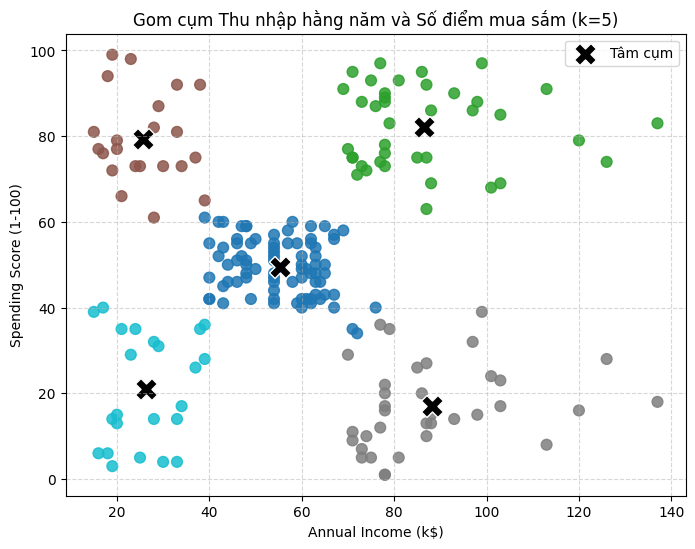

Hệ số Silhouette (Thu nhập & Điểm mua sắm, k=5): 0.5539


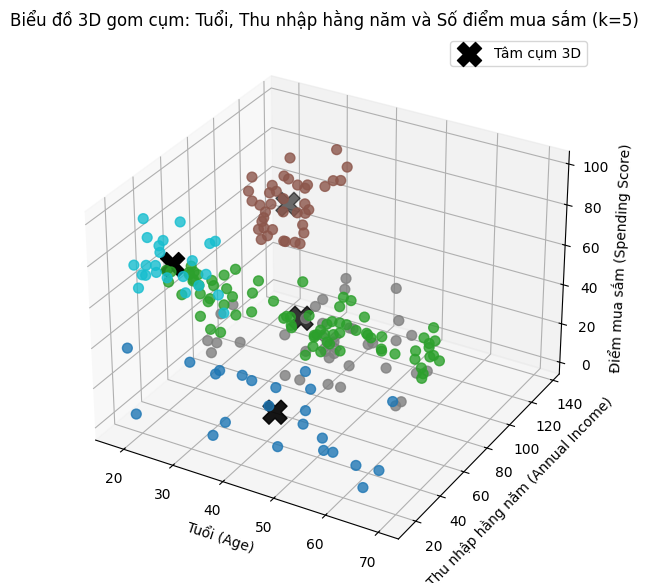

Hệ số Silhouette (3 thuộc tính 3D, k=5): 0.4443


In [11]:
# CÂU 9)
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

# --- PHẦN 1: Gom cụm Thu nhập hằng năm và Số điểm mua sắm (k=5) ---
X_income_spending = df[['Annual Income (k$)', 'Spending Score (1-100)']].values
kmeans_inc = KMeans(n_clusters=5, init='k-means++', random_state=42, n_init=10)
clusters_inc = kmeans_inc.fit_predict(X_income_spending)

plt.figure(figsize=(8, 6))
plt.scatter(X_income_spending[:, 0], X_income_spending[:, 1], c=clusters_inc, cmap='tab10', s=60, alpha=0.85)
plt.scatter(kmeans_inc.cluster_centers_[:, 0], kmeans_inc.cluster_centers_[:, 1], c='black', s=250, marker='X', label='Tâm cụm', edgecolor='white')
plt.title("Gom cụm Thu nhập hằng năm và Số điểm mua sắm (k=5)")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

sil_inc = silhouette_score(X_income_spending, clusters_inc)
print(f"Hệ số Silhouette (Thu nhập & Điểm mua sắm, k=5): {sil_inc:.4f}")

# --- PHẦN 2: Gom cụm 3 thuộc tính (Tuổi, Thu nhập hằng năm, Số điểm mua sắm) vẽ biểu đồ 3D ---
X_3d = df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].values
kmeans_3d = KMeans(n_clusters=5, init='k-means++', random_state=42, n_init=10)
clusters_3d = kmeans_3d.fit_predict(X_3d)

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X_3d[:, 0], X_3d[:, 1], X_3d[:, 2], c=clusters_3d, cmap='tab10', s=50, alpha=0.8)
ax.scatter(kmeans_3d.cluster_centers_[:, 0], kmeans_3d.cluster_centers_[:, 1], kmeans_3d.cluster_centers_[:, 2],
           c='black', s=300, marker='X', label='Tâm cụm 3D')

ax.set_title("Biểu đồ 3D gom cụm: Tuổi, Thu nhập hằng năm và Số điểm mua sắm (k=5)")
ax.set_xlabel('Tuổi (Age)')
ax.set_ylabel('Thu nhập hằng năm (Annual Income)')
ax.set_zlabel('Điểm mua sắm (Spending Score)')
ax.legend()
plt.show()

sil_3d = silhouette_score(X_3d, clusters_3d)
print(f"Hệ số Silhouette (3 thuộc tính 3D, k=5): {sil_3d:.4f}")